# TP 6 · Choisir et défendre un modèle

AI4I 2020. **Mêmes observations de validation pour tous les modèles** : c'est la condition pour que la comparaison soit équitable.

## 0. Reprise : splits et preprocessing du TP 1

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import precision_score, recall_score, confusion_matrix

df = pd.read_csv("data/ai4i2020.csv")
TARGET = "Machine failure"
NUM_COLS = ["Torque [Nm]", "Air temperature [K]", "Process temperature [K]",
            "Rotational speed [rpm]", "Tool wear [min]"]
CAT_COLS = ["Type"]
X = df[NUM_COLS + CAT_COLS]
Y = df[TARGET]

# mêmes splits que les TP 1 et 3 : 60 / 20 / 20, stratifiés
X_train, X_tmp, Y_train, Y_tmp = train_test_split(X, Y, test_size=0.4, stratify=Y, random_state=42)
X_val, X_test, Y_val, Y_test   = train_test_split(X_tmp, Y_tmp, test_size=0.5, stratify=Y_tmp, random_state=42)

# même preprocessing, fit sur train uniquement
preprocess = ColumnTransformer([
    ("num", StandardScaler(), NUM_COLS),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
])
preprocess.fit(X_train)
print(len(X_train), len(X_val), len(X_test), "| pannes en validation :", Y_val.sum())

6000 2000 2000 | pannes en validation : 68


## 1. Définir une metric principale et une contrainte de décision

**Contexte métier :** une alerte déclenche le contrôle d'une machine. Rater une panne coûte cher (arrêt de production) ; une fausse alerte coûte un contrôle inutile. Mais trop de fausses alertes et les techniciens finissent par **ignorer** le système.

**Metric principale : le recall** (part des pannes détectées).
**Contrainte de décision : precision ≥ 50 %**, au moins une alerte sur deux doit être une vraie panne.

Concrètement, pour chaque modèle, on choisit **sur la validation** le threshold qui donne le **meilleur recall tout en gardant une precision ≥ 50 %**.

**Metric secondaire : l'average precision (AP)**, l'aire sous la courbe precision-recall. Elle ne dépend d'aucun threshold et résume la capacité du modèle à bien **classer** les machines (pannes en haut, normales en bas). Hasard ≈ 0,034 (le taux de pannes).

In [2]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import time

P_MIN = 0.5

def evaluer(name, scores, temps, lisibilite):
    """Choisit le threshold (meilleur recall avec precision >= P_MIN) et renvoie une ligne de journal."""
    prec, rec, thr = precision_recall_curve(Y_val, scores)
    ok = prec[:-1] >= P_MIN
    i = int(np.argmax(np.where(ok, rec[:-1], -1)))
    t = thr[i]
    p = (scores >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(Y_val, p).ravel()
    return {"essai": name, "threshold": round(float(t), 3),
            "recall": recall_score(Y_val, p), "precision": precision_score(Y_val, p),
            "AP": average_precision_score(Y_val, scores),
            "pannes détectées": f"{tp} / {tp + fn}", "fausses alertes": fp,
            "temps d'entraînement (s)": round(temps, 2), "lisibilité": lisibilite}

journal, all_scores = [], {}

## 2. Comparer logistic regression, tree et MLP

Tous entraînés sur le **même train**, évalués sur la **même validation**, avec la **même règle de threshold**.

In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

sk_models = {
    "logistic regression": (make_pipeline(clone(preprocess), LogisticRegression(max_iter=1000)),
                            "bonne : un poids par feature"),
    "tree (depth 3)":      (make_pipeline(clone(preprocess), DecisionTreeClassifier(max_depth=3, random_state=42)),
                            "excellente : 3 règles lisibles"),
}
fitted = {}
for name, (m, lisib) in sk_models.items():
    t0 = time.time(); m.fit(X_train, Y_train); dt = time.time() - t0
    fitted[name] = m
    all_scores[name] = m.predict_proba(X_val)[:, 1]
    journal.append(evaluer(name, all_scores[name], dt, lisib))

### Le MLP

Deux versions, pour documenter l'effet des réglages (une modification à la fois) :
- **MLP 16** : celui du TP 4 (16 neurones, lr 1e-3, 20 epochs) ;
- **MLP 64** : plus large (64 neurones) **et** learning rate plus grand (1e-2), 20 epochs. Le TP 4 avait montré que le petit MLP n'avait pas fini d'apprendre.

Pour chaque MLP, on garde **le meilleur état sur la validation** (loss de validation minimale).

In [4]:
from copy import deepcopy
from torch.utils.data import TensorDataset, DataLoader

X_train_t = torch.tensor(preprocess.transform(X_train), dtype=torch.float32)
y_train_t = torch.tensor(Y_train.to_numpy(), dtype=torch.float32)
X_val_t   = torch.tensor(preprocess.transform(X_val), dtype=torch.float32)
y_val_t   = torch.tensor(Y_val.to_numpy(), dtype=torch.float32)
loss_fn = nn.BCEWithLogitsLoss()

def train_mlp(hidden, lr, epochs=20):
    torch.manual_seed(42)
    model = nn.Sequential(nn.Linear(8, hidden), nn.ReLU(), nn.Linear(hidden, 1))
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=64, shuffle=True)
    best, best_state, best_epoch = float("inf"), None, 0
    for epoch in range(1, epochs + 1):
        model.train()
        for xb, yb in loader:
            opt.zero_grad()
            loss_fn(model(xb).squeeze(1), yb).backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            val = loss_fn(model(X_val_t).squeeze(1), y_val_t).item()
        if val < best:
            best, best_state, best_epoch = val, deepcopy(model.state_dict()), epoch
    model.load_state_dict(best_state); model.eval()
    return model, best_epoch, best

mlps = {}
for name, hidden, lr in [("MLP 16 (lr 1e-3)", 16, 1e-3), ("MLP 64 (lr 1e-2)", 64, 1e-2)]:
    t0 = time.time(); m, ep, vl = train_mlp(hidden, lr); dt = time.time() - t0
    mlps[name] = m
    with torch.no_grad():
        all_scores[name] = torch.sigmoid(m(X_val_t).squeeze(1)).numpy()
    journal.append(evaluer(name, all_scores[name], dt, "faible : boîte noire"))
    print(f"{name} : meilleur état à l'epoch {ep}, loss val {vl:.4f}")

MLP 16 (lr 1e-3) : meilleur état à l'epoch 20, loss val 0.0988
MLP 64 (lr 1e-2) : meilleur état à l'epoch 20, loss val 0.0690


In [5]:
journal_df = pd.DataFrame(journal).set_index("essai")
journal_df.round(3)

,threshold,recall,precision,AP,pannes détectées,fausses alertes,temps d'entraînement (s),lisibilité
essai,,,,,,,,
logistic regression,0.260,0.382,0.500,0.432,26 / 68,26,0.02,bonne : un poids par feature
tree (depth 3),0.444,0.191,0.591,0.235,13 / 68,9,0.01,excellente : 3 règles lisibles
MLP 16 (lr 1e-3),0.290,0.353,0.500,0.442,24 / 68,24,3.63,faible : boîte noire
MLP 64 (lr 1e-2),0.279,0.721,0.500,0.686,49 / 68,49,2.01,faible : boîte noire


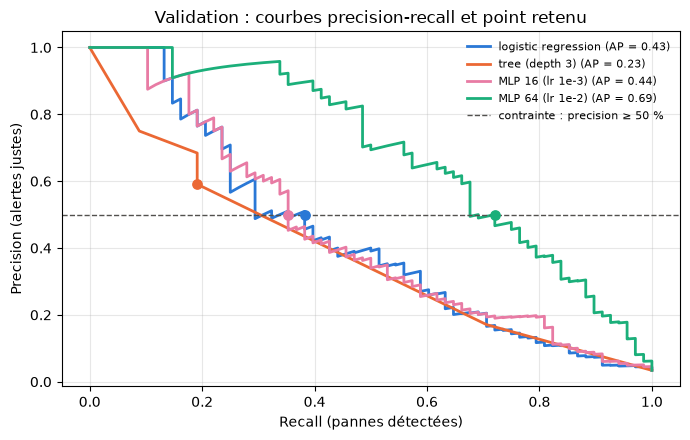

In [6]:
colors = {"logistic regression": "#2a78d6", "tree (depth 3)": "#eb6834",
          "MLP 16 (lr 1e-3)": "#e87ba4", "MLP 64 (lr 1e-2)": "#1baf7a"}
fig, ax = plt.subplots(figsize=(7, 4.5))
for name, s in all_scores.items():
    prec, rec, _ = precision_recall_curve(Y_val, s)
    ax.plot(rec, prec, color=colors[name], lw=2,
            label=f"{name} (AP = {average_precision_score(Y_val, s):.2f})")
    r = journal_df.loc[name]
    ax.scatter(r["recall"], r["precision"], color=colors[name], s=45, zorder=3)
ax.axhline(P_MIN, ls="--", color="#52514e", lw=1, label="contrainte : precision ≥ 50 %")
ax.set_xlabel("Recall (pannes détectées)"); ax.set_ylabel("Precision (alertes justes)")
ax.set_title("Validation : courbes precision-recall et point retenu")
ax.legend(frameon=False, fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Les **points** marquent le threshold retenu pour chaque modèle (meilleur recall au-dessus de la ligne pointillée).

## 3. Examiner cinq erreurs

On prend le modèle en tête (**MLP 64**) à son threshold, et on regarde **cinq pannes ratées** (faux négatifs), les erreurs les plus coûteuses. On affiche les valeurs **brutes** des features et la **puissance** (couple × vitesse angulaire, en W), utile pour interpréter.

In [7]:
best_name = "MLP 64 (lr 1e-2)"
t_best = journal_df.loc[best_name, "threshold"]
s_best = all_scores[best_name]

erreurs = X_val.copy()
erreurs["panne réelle"] = Y_val.values
erreurs["score MLP"] = s_best.round(3)
erreurs["alerte"] = (s_best >= t_best).astype(int)
erreurs["puissance (W)"] = (erreurs["Torque [Nm]"] * erreurs["Rotational speed [rpm]"] * 2 * np.pi / 60).round(0)
# les modes de panne, UNIQUEMENT pour comprendre l'erreur après coup (jamais comme feature)
erreurs = erreurs.join(df[["TWF", "HDF", "PWF", "OSF", "RNF"]])

ratees = erreurs[(erreurs["panne réelle"] == 1) & (erreurs["alerte"] == 0)]
print(f"{len(ratees)} pannes ratées au threshold {t_best}")
ratees.sort_values("score MLP").head(5)

20 pannes ratées au threshold 0.279


,Torque [Nm],Air temperature [K],Process temperature [K],Rotational speed [rpm],Tool wear [min],Type,panne réelle,score MLP,alerte,puissance (W),TWF,HDF,PWF,OSF,RNF
8506,27.3,298.4,309.6,1710,163,L,1,0.001,0,4889.0,0,0,0,0,0
1996,38.2,298.4,308.0,1416,198,M,1,0.002,0,5664.0,1,0,0,0,0
8690,44.4,297.1,308.5,1323,207,L,1,0.011,0,6151.0,1,0,0,0,0
2671,41.9,299.7,309.3,1399,221,M,1,0.025,0,6138.0,1,0,0,0,0
9174,25.6,297.8,308.9,1871,200,L,1,0.025,0,5016.0,1,0,0,0,0


In [8]:
print("Modes de panne parmi TOUTES les pannes ratées :")
print(ratees[["TWF", "HDF", "PWF", "OSF", "RNF"]].sum())
print()
print("Modes de panne parmi les pannes détectées :")
detectees = erreurs[(erreurs["panne réelle"] == 1) & (erreurs["alerte"] == 1)]
print(detectees[["TWF", "HDF", "PWF", "OSF", "RNF"]].sum())

Modes de panne parmi TOUTES les pannes ratées :
TWF    10
HDF     6
PWF     1
OSF     0
RNF     0
dtype: int64

Modes de panne parmi les pannes détectées :
TWF     2
HDF    16
PWF    15
OSF    21
RNF     0
dtype: int64


**Lecture des erreurs** (les colonnes TWF…RNF servent ici **uniquement à comprendre après coup**, jamais comme entrées du modèle) :

Sur les 20 pannes ratées en validation :
- **10 sont des TWF (usure de l'outil)**, contre seulement 2 TWF détectées. Dans AI4I, cette panne arrive à une usure élevée mais à un moment **tiré au hasard** entre ~200 et 240 min. Une machine à 210 min d'usure peut tomber en panne ou non : le modèle ne peut pas trancher. C'est la principale faiblesse.
- **6 sont des HDF (surchauffe)**, alors que 16 HDF sont détectées : ce sont des cas proches de la limite de la règle.
- **3 n'ont aucun mode de panne renseigné** (ligne 8506 par exemple) : `Machine failure = 1` sans cause connue. C'est une bizarrerie connue du dataset, ces pannes ressemblent à des machines normales.
- À l'inverse, les pannes de **puissance (PWF)** et de **surcharge (OSF)** sont presque toutes détectées (15/16 et 21/21) : ce sont des règles à seuils sur le torque, la vitesse et l'usure, que le MLP a appris à reproduire.

Les 5 erreurs affichées ont des scores très bas (0,001 à 0,025) et des valeurs de capteurs **banales** (torque 25-44 Nm, vitesse 1300-1900 rpm) : elles ressemblent vraiment à des machines normales. Seule l'usure, autour de 200 min, est un indice, trop faible pour déclencher une alerte.

### Le journal d'essais complété

In [9]:
journal_df["conclusion"] = [
    "Baseline apprise. Correcte, frontière linéaire : ne capte pas les deux extrêmes du torque.",
    "Très lisible, mais trop peu de feuilles : peu de thresholds possibles, recall faible.",
    "Même niveau que la logistic regression : trop petit / pas assez entraîné (cf. TP 4).",
    "Meilleur recall et meilleure AP : la non-linéarité capte les règles à seuils (puissance, usure × torque).",
]
journal_df[["threshold", "recall", "precision", "AP", "pannes détectées", "fausses alertes",
            "temps d'entraînement (s)", "lisibilité", "conclusion"]].round(3)

,threshold,recall,precision,AP,pannes détectées,fausses alertes,temps d'entraînement (s),lisibilité,conclusion
essai,,,,,,,,,
logistic regression,0.260,0.382,0.500,0.432,26 / 68,26,0.02,bonne : un poids par feature,"Baseline apprise. Correcte, frontière linéaire..."
tree (depth 3),0.444,0.191,0.591,0.235,13 / 68,9,0.01,excellente : 3 règles lisibles,"Très lisible, mais trop peu de feuilles : peu ..."
MLP 16 (lr 1e-3),0.290,0.353,0.500,0.442,24 / 68,24,3.63,faible : boîte noire,Même niveau que la logistic regression : trop ...
MLP 64 (lr 1e-2),0.279,0.721,0.500,0.686,49 / 68,49,2.01,faible : boîte noire,Meilleur recall et meilleure AP : la non-linéa...


## 4. Justifier le choix : résultat, coût et limites

### Évaluation finale sur le test (une seule fois, après le choix)

In [10]:
X_test_t = torch.tensor(preprocess.transform(X_test), dtype=torch.float32)
with torch.no_grad():
    s_test = torch.sigmoid(mlps[best_name](X_test_t).squeeze(1)).numpy()
p_test = (s_test >= t_best).astype(int)
tn, fp, fn, tp = confusion_matrix(Y_test, p_test).ravel()
print(f"{best_name}, threshold {t_best} (choisi sur validation)")
print(f"Test : recall {recall_score(Y_test, p_test):.2f} | precision {precision_score(Y_test, p_test):.2f}")
print(f"{tp} pannes détectées sur {tp + fn}, {fp} fausses alertes")

# même chose pour la logistic regression, pour mesurer le gain réel
t_log = journal_df.loc["logistic regression", "threshold"]
p_log = (fitted["logistic regression"].predict_proba(X_test)[:, 1] >= t_log).astype(int)
print(f"Logistic regression sur le test : recall {recall_score(Y_test, p_log):.2f} | precision {precision_score(Y_test, p_log):.2f}")

MLP 64 (lr 1e-2), threshold 0.279 (choisi sur validation)
Test : recall 0.82 | precision 0.55
56 pannes détectées sur 68, 45 fausses alertes
Logistic regression sur le test : recall 0.44 | precision 0.58


### Décision : **MLP 64 neurones (lr 1e-2), threshold choisi sur validation**

**Résultat.** Sous la contrainte precision ≥ 50 %, c'est de loin le meilleur recall : il détecte environ **deux fois plus de pannes** que la logistic regression sur la validation, et son AP (~0,69) est bien au-dessus des autres (~0,43 pour la logit et le MLP 16, ~0,24 pour l'arbre). Le gain se confirme sur le test, évalué une seule fois.

**Coût.**
- Entraînement : quelques secondes, contre quelques centièmes de seconde pour la logit : négligeable à cette échelle.
- Prédiction : instantanée, aucun problème pour un usage en usine.
- **Explicabilité : c'est le vrai coût.** On ne peut pas lire ses règles comme celles de l'arbre. Il faudra des outils comme l'importance par permutation pour expliquer ses alertes aux techniciens.

**Pourquoi pas les autres ?**
- La **logistic regression** reste un bon plan B, simple et lisible, mais sa frontière linéaire ne capte pas que **les deux extrêmes** du torque sont dangereux (TP 0).
- L'**arbre de profondeur 3** est le plus lisible, mais 8 feuilles ne suffisent pas.
- Le **MLP 16** montre que « réseau de neurones » ne veut pas dire « meilleur » : mal réglé, il ne fait pas mieux qu'une logistic regression.

**Limites.**
- **68 pannes** en validation : quelques pannes de plus ou de moins font bouger le recall de plusieurs points. Une cross-validation ou plusieurs seeds rendraient le classement plus solide.
- Le threshold est **choisi** sur la validation, donc les chiffres de validation sont un peu optimistes ; seul le test donne une estimation honnête.
- Une partie des pannes (usure TWF, aléatoire RNF) est **imprévisible** avec ces capteurs : aucun modèle ne les rattrapera.
- AI4I est un dataset **synthétique** : le MLP a surtout appris les règles de la simulation. Sur une vraie usine, tout serait à revalider.